# Science case: transient classification for time-domain and multi-messenger follow-up

Spectroscopic follow-up of transients is mostly classification: a low-SNR spectrum, rebinned to
R ~ 100 to 300, that tells a SN Ia from a SN II, a kilonova from an afterglow, or a tidal
disruption event from an AGN flare. For LFAST the question is how faint a transient can be
classified in a given exposure, and how soon after the alert.

Assumptions, changeable in the first code cell:

* Classification needs SNR 5 per rebinned element at $R_{bin}$ = 300 across 450 to 650 nm, the
  regime low-resolution classifiers are built for (SEDM: Blagorodnova et al. 2018; 4MOST TiDES:
  Swann et al. 2019). Co-adding $k = R/R_{bin}$ adjacent resels of equal SNR raises the SNR by
  exactly $\sqrt{k}$ in this noise model, because every variance term scales with the number of
  pixels.
* Transient SEDs: a 12,000 K blackbody (young SN or shock cooling), a 6000 K blackbody (SN Ia
  near peak), a 3500 K blackbody (late kilonova or late SN II), and a power law
  $F_\nu \propto \nu^{-0.7}$ for a GRB afterglow. Magnitudes are R (Cousins; within 0.1 to 0.2
  mag of SDSS r for these colours), so the SED colour matters inside the 450 to 650 nm window.
* Kilonova: AT2017gfo-like, r = 17.3 at 0.5 d at 40 Mpc, fading 0.95 mag per day in r over the
  first 5 days (Drout et al. 2017, Table S2), cooling from ~10,000 K at 0.5 d to ~5000 K at
  1.5 d and approaching ~2500 K after ~5 d (Drout et al. 2017; Shappee et al. 2017).
* Sky: the bundled grey-time table (moon up). Dark time is 0.3 to 0.5 mag deeper at the faint
  end (notebook 02).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
# ---- knobs ----
N_TEL = 20
WINDOW = (450, 650)          # nm, classification window
R_BIN = 300                  # rebinned resolution for classification
SNR_CLASS = 5                # SNR per R_BIN element needed to classify
BAND = "R"                   # magnitudes in Cousins R (~ SDSS r)

bench = LFASTETC("bench_r1800", n_telescopes=N_TEL, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = bench.instrument.resolving_power / R_BIN   # resels per rebinned element
snr_resel_needed = SNR_CLASS / np.sqrt(k)      # SNR per native resel that gives SNR_CLASS at R_BIN
print(f"{k:.1f} resels per R={R_BIN} bin -> need SNR {snr_resel_needed:.2f} per resel")

seds = {"blue 12,000 K": Source.blackbody(12000, 0, BAND),
        "SN Ia-like 6000 K": Source.blackbody(6000, 0, BAND),
        "red 3500 K": Source.blackbody(3500, 0, BAND),
        "afterglow Fnu~nu^-0.7": Source.powerlaw(-0.7, 0, BAND, system="AB")}

6.0 resels per R=300 bin -> need SNR 2.04 per resel


## Exposure time to classify versus magnitude

At the same R magnitude the blue SED reaches deepest and the red one shallowest, by about 0.8
mag. The magnitude is fixed at 641 nm, at the red edge of the classification window, so a blue
SED puts more light into 450 to 650 nm than a red one, and that outweighs the lower throughput
in the blue. The afterglow power law behaves like the blue blackbody.

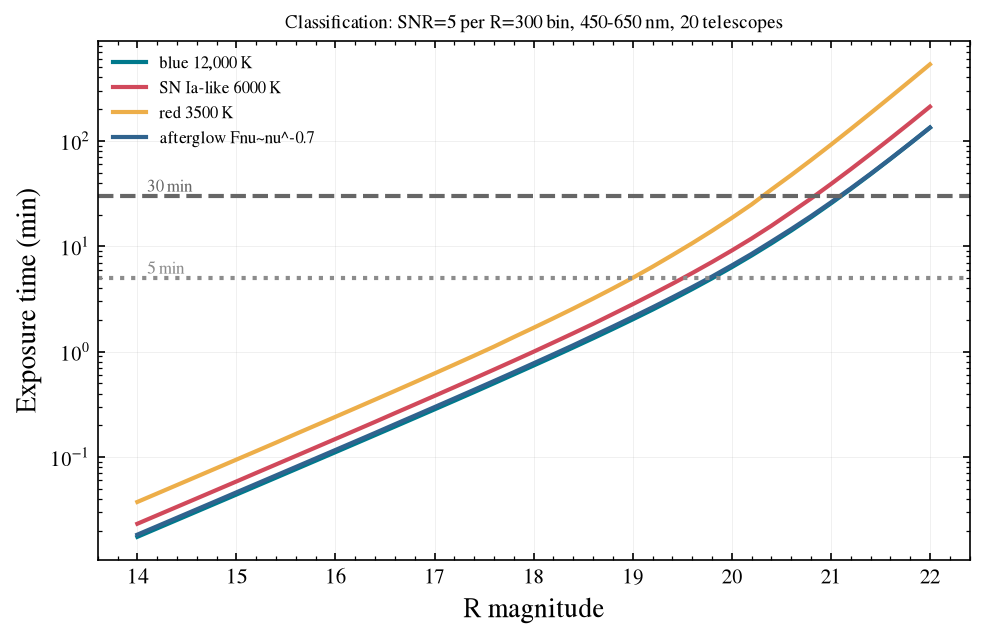

In [3]:
mags = np.linspace(14, 22, 41)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, src in seds.items():
    t = bench.exptime_vs_mag(src, mags, snr=snr_resel_needed, wavelength=WINDOW)
    ax.plot(mags, t/60, label=label)
ax.set_yscale('log'); ax.set_xlabel(f"{BAND} magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(30, color='0.4', ls='--'); ax.text(14.1, 33, "30 min", fontsize=8, color='0.4')
ax.axhline(5, color='0.55', ls=':'); ax.text(14.1, 5.5, "5 min", fontsize=8, color='0.55')
ax.legend(fontsize=8); ax.set_title(f"Classification: SNR={SNR_CLASS} per R={R_BIN} bin, {WINDOW[0]}-{WINDOW[1]} nm, {N_TEL} telescopes", fontsize=9);

## Classification depth versus exposure time

In [4]:
for exp in (300, 900, 1800, 3600):
    lims = [f"{label}: {BAND}<{bench.limiting_magnitude(src, exp, snr_resel_needed, wavelength=WINDOW):.1f}"
            for label, src in seds.items()]
    print(f"{exp:5d} s   " + " | ".join(lims))

  300 s   blue 12,000 K: R<19.8 | SN Ia-like 6000 K: R<19.5 | red 3500 K: R<19.0 | afterglow Fnu~nu^-0.7: R<19.8
  900 s   blue 12,000 K: R<20.6 | SN Ia-like 6000 K: R<20.4 | red 3500 K: R<19.8 | afterglow Fnu~nu^-0.7: R<20.6
 1800 s   blue 12,000 K: R<21.1 | SN Ia-like 6000 K: R<20.8 | red 3500 K: R<20.3 | afterglow Fnu~nu^-0.7: R<21.1
 3600 s   blue 12,000 K: R<21.5 | SN Ia-like 6000 K: R<21.3 | red 3500 K: R<20.7 | afterglow Fnu~nu^-0.7: R<21.5


## Kilonova: how many days after merger can we still classify?

AT2017gfo at 40 Mpc: r = 17.3 at 0.5 d, fading 0.95 mag per day in r, cooling 10,000 K to 5000 K
to 2500 K at 0.5, 1.5 and 5.5 d (linear ramps). We scale to other distances with the distance
modulus and ask for a classification spectrum (SNR 5 at R = 300) in a 30 minute exposure. The
blackbody is normalised in R, so the cooling changes how much of the light falls inside the
classification window.

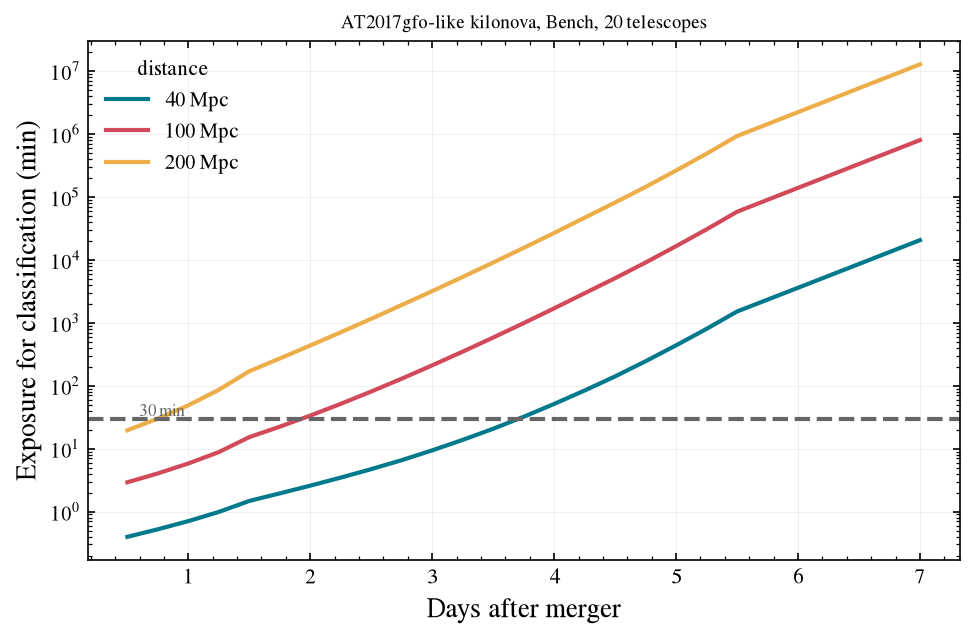

In [5]:
days = np.linspace(0.5, 7, 27)
def kn_mag(d, D_Mpc):
    return 17.3 + 0.95*(d-0.5) + 5*np.log10(D_Mpc/40)
def kn_teff(d):
    return np.interp(d, [0.5, 1.5, 5.5], [10000, 5000, 2500])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for D in (40, 100, 200):
    t_needed = np.array([bench.exptime_vs_mag(Source.blackbody(kn_teff(d), 0, BAND), [kn_mag(d, D)],
                                              snr=snr_resel_needed, wavelength=WINDOW)[0] for d in days])
    ax.plot(days, t_needed/60, label=f"{D} Mpc")
ax.axhline(30, color='0.4', ls='--'); ax.text(0.6, 33, "30 min", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_xlabel("Days after merger"); ax.set_ylabel("Exposure for classification (min)")
ax.legend(title="distance"); ax.set_title("AT2017gfo-like kilonova, Bench, 20 telescopes", fontsize=9);

## Rapid response: a fading afterglow

GRB afterglows fade as $F \propto t^{-\alpha}$ with $\alpha \sim 1$. For an afterglow at
R = 17 (AB) one hour after the burst, the plot shows how the time needed to classify grows with
the delay before LFAST is on target. A fiber-fed array with no instrument changes can in
principle respond within minutes, which is the regime where the curve is flat.

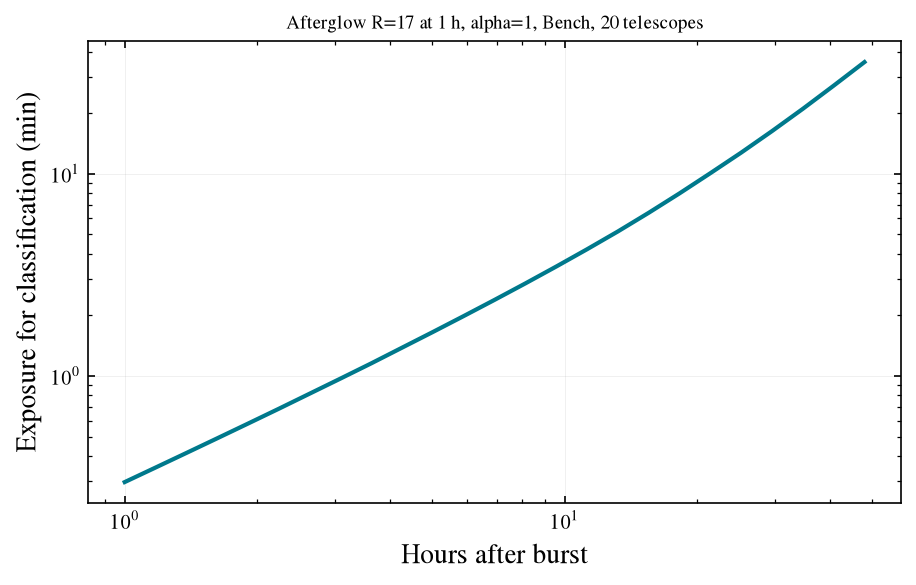

In [6]:
delay_h = np.logspace(0, np.log10(48), 25)
mag_t = 17 + 2.5*1.0*np.log10(delay_h/1.0)
t_cls = bench.exptime_vs_mag(seds["afterglow Fnu~nu^-0.7"], mag_t, snr=snr_resel_needed, wavelength=WINDOW)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(delay_h, t_cls/60)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel("Hours after burst"); ax.set_ylabel("Exposure for classification (min)")
ax.set_title("Afterglow R=17 at 1 h, alpha=1, Bench, 20 telescopes", fontsize=9);

## Array size and classification depth in 30 minutes

In [7]:
for n in (5, 10, 20, 40, 80):
    e = LFASTETC("bench_r1800", n_telescopes=n, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
    print(f"N={n:3d}: classification depth in 30 min, 6000 K: {BAND}<{e.limiting_magnitude(seds['SN Ia-like 6000 K'], 1800, snr_resel_needed, wavelength=WINDOW):.2f}")

N=  5: classification depth in 30 min, 6000 K: R<19.84
N= 10: classification depth in 30 min, 6000 K: R<20.37
N= 20: classification depth in 30 min, 6000 K: R<20.84
N= 40: classification depth in 30 min, 6000 K: R<21.23
N= 80: classification depth in 30 min, 6000 K: R<21.61


## Things to try

* Raise `SNR_CLASS` to 10, the level at which a SN Ia subtype can be told apart. How much depth
  does that cost?
* Use `Sky(scale=0.4)` for dark time and redo the kilonova plot. Does the 200 Mpc curve cross the
  30 minute line?